In [31]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [16]:
# Load the cleaned datasets
sales = pd.read_parquet("../data/cleaned/sales_cleaned.parquet")
customers = pd.read_parquet("../data/cleaned/customers_cleaned.parquet")
products = pd.read_parquet("../data/cleaned/products_cleaned.parquet")
stores = pd.read_parquet("../data/cleaned/stores_cleaned.parquet")
promotions = pd.read_parquet("../data/cleaned/promotions_cleaned.parquet")
holidays = pd.read_parquet("../data/cleaned/public_holidays_cleaned.parquet")
cpi = pd.read_parquet("../data/cleaned/national_cpi_monthly_cleaned.parquet")

## Do the product categories have different average sales-line values?
We'll use the Kruskal–Wallis test, a non-parametric test that compares the distributions of three or more independent groups. It is useful when we don't want to assume that sales-line values are normally distributed.

In [18]:

# Remove records that cannot be used in this test.
category_data = sales.dropna(subset=["Category", "SalesValue"]).copy()

# Keep categories with at least one valid observation.
category_groups = [
    group["SalesValue"].to_numpy()
    for _, group in category_data.groupby("Category")
    if len(group) > 0
]

# Run the Kruskal-Wallis test.
if len(category_groups) >= 2:
    statistic, p_value = stats.kruskal(*category_groups)

    print("Kruskal-Wallis test: Sales value by product category")
    print(f"Number of categories: {len(category_groups)}")
    print(f"Test statistic: {statistic:.4f}")
    print(f"P-value: {p_value:.6f}")

    # Compare the p-value with the 5% significance level.
    if p_value < 0.05:
        print("Result: Evidence of a difference between at least two categories.")
    else:
        print("Result: Insufficient evidence of a difference between categories.")
else:
    print("The test requires at least two categories with valid sales values.")


Kruskal-Wallis test: Sales value by product category
Number of categories: 4
Test statistic: 846.3533
P-value: 0.000000
Result: Evidence of a difference between at least two categories.


The Kruskal–Wallis test produced a test statistic of 846.3533 and a p-value below 0.001, indicating a statistically significant difference in sales-value distributions across the four product categories. This suggests that product categories do not all generate similar sales-line values in the synthetic dataset.


## Do sales values vary across days of the week?

In [19]:

# Calculate the total estimated sales value for each day.
daily_sales = (
    sales.groupby("SaleDate", as_index=False)["SalesValue"]
    .sum()
)

# Add the weekday name to each date.
daily_sales["Weekday"] = daily_sales["SaleDate"].dt.day_name()

# Arrange weekdays in calendar order.
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Display the number of days and average estimated sales per weekday.
weekday_summary = (
    daily_sales.groupby("Weekday")["SalesValue"]
    .agg(["count", "mean", "median", "std"])
    .reindex(weekday_order)
)

print("Estimated daily sales by weekday:")
display(weekday_summary.round(2))

# Build one group of daily sales values for each weekday.
weekday_groups = [
    group["SalesValue"].to_numpy()
    for _, group in daily_sales.groupby("Weekday")
    if len(group) > 0
]

# Test whether daily sales distributions differ across weekdays.
if len(weekday_groups) >= 2:
    statistic, p_value = stats.kruskal(*weekday_groups)

    print("\nKruskal-Wallis test: Daily sales by weekday")
    print(f"Test statistic: {statistic:.4f}")
    print(f"P-value: {p_value:.6f}")

    if p_value < 0.05:
        print("Result: Evidence that daily sales distributions differ by weekday.")
    else:
        print("Result: Insufficient evidence of weekday differences.")


Estimated daily sales by weekday:


,count,mean,median,std
Weekday,,,,
Monday,52,48528.92,43532.5,26855.92
Tuesday,52,53671.38,43782.5,32712.63
Wednesday,53,49077.74,42494.0,27601.31
Thursday,52,40345.69,34278.0,21978.94
Friday,52,48221.65,41418.5,22322.48
Saturday,52,48866.10,42241.5,27662.63
Sunday,52,45327.21,41104.0,22274.91



Kruskal-Wallis test: Daily sales by weekday
Test statistic: 6.1658
P-value: 0.404873
Result: Insufficient evidence of weekday differences.



Tuesday recorded the highest average estimated daily sales (KSh 53,671.38), while Thursday recorded the lowest (KSh 40,345.69). However, the Kruskal–Wallis test returned a p-value of 0.4049, which is greater than the 0.05 significance level. Therefore, there is insufficient statistical evidence to conclude that estimated daily sales distributions differ across the seven weekdays. Although the averages vary, these observed differences may reflect normal variation rather than a consistent weekday effect.


## Are sales higher when promotions are running?

In [20]:
# Compare sales on promotion and non-promotion days
sales["Date"] = sales["TransactionDate"].dt.normalize()

promotions["StartDate"] = pd.to_datetime(promotions["StartDate"])
promotions["EndDate"] = pd.to_datetime(promotions["EndDate"])

promotion_dates = set()

for _, promo in promotions.iterrows():
    dates = pd.date_range(promo["StartDate"], promo["EndDate"])
    promotion_dates.update(dates.normalize())

sales["HasPromotion"] = sales["Date"].isin(promotion_dates)

daily_sales = sales.groupby(["Date", "HasPromotion"])["SalesValue"].sum().reset_index()

print("Average daily sales:")
print(daily_sales.groupby("HasPromotion")["SalesValue"].mean())

promo_sales = daily_sales[daily_sales["HasPromotion"]]["SalesValue"]
normal_sales = daily_sales[~daily_sales["HasPromotion"]]["SalesValue"]

if len(promo_sales) > 0 and len(normal_sales) > 0:
    result = stats.mannwhitneyu(promo_sales, normal_sales, alternative="two-sided")
    print("\nP-value:", round(result.pvalue, 4))

    if result.pvalue < 0.05:
        print("Result: Sales differ between promotion and non-promotion days.")
    else:
        print("Result: No clear evidence of a difference in sales.")
else:
    print("Not enough promotion or non-promotion days to compare.")

Average daily sales:
HasPromotion
False    48855.344978
True     45817.764706
Name: SalesValue, dtype: float64

P-value: 0.0846
Result: No clear evidence of a difference in sales.


Average estimated daily sales were KSh 45,817.76 on promotion days, compared with KSh 48,855.34 on non-promotion days. This represents a difference of KSh 3,037.58, with lower average sales on promotion days.
The Mann–Whitney U test returned a p-value of 0.0846, which is above the 0.05 significance level. Therefore, there is no clear statistical evidence of a difference in daily sales between promotion and non-promotion days.

## Is there a relationship between monthly sales and inflation?

In [21]:
# Group sales by month
sales["Month"] = sales["TransactionDate"].dt.to_period("M").dt.to_timestamp()

monthly_sales = sales.groupby("Month")["SalesValue"].sum().reset_index()
monthly_sales = monthly_sales.rename(columns={"SalesValue": "EstimatedSales"})

# Prepare monthly CPI data
cpi["Date"] = pd.to_datetime(cpi["Date"])
cpi["Month"] = cpi["Date"].dt.to_period("M").dt.to_timestamp()

monthly_cpi = cpi.sort_values("Date").drop_duplicates("Month", keep="last")
monthly_cpi = monthly_cpi[["Month", "Cpi"]]

# Combine sales and CPI for the same months
sales_cpi = monthly_sales.merge(monthly_cpi, on="Month").dropna()

print("Number of months compared:", len(sales_cpi))

# Check the relationship between sales and CPI
if len(sales_cpi) >= 6 and sales_cpi["EstimatedSales"].nunique() > 1 and sales_cpi["Cpi"].nunique() > 1:
    correlation, p_value = stats.spearmanr(
        sales_cpi["EstimatedSales"],
        sales_cpi["Cpi"]
    )

    print(f"Correlation: {correlation:.4f}")
    print(f"P-value: {p_value:.4f}")

    if p_value < 0.05:
        print("Result: Sales and CPI appear to be related.")
    else:
        print("Result: No clear evidence that sales and CPI are related.")
else:
    print("Not enough data to check the relationship.")

Number of months compared: 12
Correlation: 0.3287
P-value: 0.2969
Result: No clear evidence that sales and CPI are related.



The analysis compared monthly estimated sales with the Consumer Price Index (CPI) across 12 months. The correlation was 0.3287, showing a weak positive relationship: sales tended to be higher in some months when CPI was higher. However, the p-value was 0.2969, which is above the 0.05 significance level. This means there is not enough evidence to conclude that monthly sales and CPI are related in this dataset.


## When prices rise, does customer demand decrease?

In [22]:
# Compare inflation with monthly demand
sales["Month"] = sales["TransactionDate"].dt.to_period("M")

monthly_demand = sales.groupby("Month")["Quantity"].sum().reset_index()

cpi["Month"] = pd.to_datetime(cpi["Date"]).dt.to_period("M")
monthly_cpi = cpi.sort_values("Date").drop_duplicates("Month", keep="last")

data = monthly_demand.merge(monthly_cpi[["Month", "Cpi"]], on="Month").dropna()

correlation, p_value = stats.spearmanr(data["Quantity"], data["Cpi"])

print("Months compared:", len(data))
print("Correlation:", round(correlation, 4))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Result: Demand and CPI appear to be related.")
else:
    print("Result: No clear evidence that demand and CPI are related.")

Months compared: 12
Correlation: 0.028
P-value: 0.9312
Result: No clear evidence that demand and CPI are related.


The analysis compared monthly CPI with total quantities sold over 12 months. The correlation was 0.028, which is very close to zero, while the p-value was 0.9312. This means there is no clear statistical evidence of a relationship between inflation and demand in this dataset.
However, this does not prove that inflation has no effect on demand. The analysis covers only 12 months, and CPI measures general price changes rather than the prices of individual products. Further analysis by product category could reveal patterns that are not visible in total demand.

## Are some product categories more affected by rising prices than others?

In [23]:
# Compare monthly CPI with demand for each product category
sales["Month"] = sales["TransactionDate"].dt.to_period("M")
cpi["Month"] = pd.to_datetime(cpi["Date"]).dt.to_period("M")

# Get monthly demand for each category
monthly_demand = (
    sales.groupby(["Month", "Category"])["Quantity"]
    .sum()
    .reset_index()
)

# Get one CPI value per month
monthly_cpi = (
    cpi.sort_values("Date")
    .drop_duplicates("Month", keep="last")[["Month", "Cpi"]]
)

# Combine demand and CPI
data = monthly_demand.merge(monthly_cpi, on="Month").dropna()

# Check each product category separately
for category in data["Category"].unique():
    category_data = data[data["Category"] == category]

    if len(category_data) >= 6 and category_data["Quantity"].nunique() > 1 and category_data["Cpi"].nunique() > 1:
        correlation, p_value = stats.spearmanr(
            category_data["Quantity"],
            category_data["Cpi"]
        )

        print(f"\nCategory: {category}")
        print("Months compared:", len(category_data))
        print("Correlation:", round(correlation, 4))
        print("P-value:", round(p_value, 4))

        if p_value < 0.05:
            print("Result: Demand and CPI appear to be related.")
        else:
            print("Result: No clear evidence that demand and CPI are related.")
    else:
        print(f"\nCategory: {category}")
        print("Not enough data to check the relationship.")


Category: Beverages
Months compared: 12
Correlation: -0.1331
P-value: 0.6801
Result: No clear evidence that demand and CPI are related.

Category: Food
Months compared: 12
Correlation: 0.035
P-value: 0.9141
Result: No clear evidence that demand and CPI are related.

Category: Household
Months compared: 12
Correlation: -0.1608
P-value: 0.6175
Result: No clear evidence that demand and CPI are related.

Category: Personal Care
Months compared: 12
Correlation: 0.5884
P-value: 0.0441
Result: Demand and CPI appear to be related.


The analysis compared monthly CPI with product demand across four categories over 12 months. Beverages, Food and Household products showed no clear statistical evidence of a relationship with CPI.
Personal Care showed a moderate positive correlation of 0.5884, with a p-value of 0.0441. This suggests that demand for Personal Care products tended to be higher when CPI was higher in the months studied. However, this relationship does not establish that inflation caused demand to increase.

## Is there a relationship between a product’s price and its demand?

In [25]:
# Keep product prices from the products table
data = sales.drop(
    columns=["UnitPriceKsh"],
    errors="ignore"
).merge(
    products[["ProductID", "UnitPriceKsh"]],
    on="ProductID",
    how="left"
)

# Group by month
data["Month"] = data["TransactionDate"].dt.to_period("M")

monthly_prices = (
    data.groupby("Month")["UnitPriceKsh"]
    .mean()
    .reset_index(name="AveragePrice")
)

# Prepare monthly CPI
cpi["Month"] = pd.to_datetime(cpi["Date"]).dt.to_period("M")

monthly_cpi = (
    cpi.sort_values("Date")
    .drop_duplicates("Month", keep="last")[["Month", "Cpi"]]
)

# Match prices with CPI
comparison = monthly_prices.merge(
    monthly_cpi,
    on="Month",
    how="inner"
).dropna()

# Calculate the relationship
if (
    len(comparison) >= 6
    and comparison["AveragePrice"].nunique() > 1
    and comparison["Cpi"].nunique() > 1
):
    correlation, p_value = stats.spearmanr(
        comparison["AveragePrice"],
        comparison["Cpi"]
    )

    print("Months compared:", len(comparison))
    print("Correlation:", round(correlation, 4))
    print("P-value:", round(p_value, 4))

    if p_value < 0.05:
        print("Result: Retail prices and CPI appear to be related.")
    else:
        print("Result: No clear evidence that retail prices and CPI are related.")
else:
    print("Not enough data or price variation to test the relationship.")

Months compared: 12
Correlation: 0.4895
P-value: 0.1063
Result: No clear evidence that retail prices and CPI are related.


The analysis compared monthly national CPI with average catalogue prices over 12 months. The correlation was 0.4895, suggesting a moderate positive relationship between the two measures. However, the p-value was 0.1063, which is above the 0.05 significance level. Therefore, there is no clear statistical evidence of a relationship between CPI and average catalogue prices in this analysis.

This result should be interpreted cautiously because the dataset covers only 12 months and uses catalogue prices rather than actual monthly selling prices.

## Monthly product prices vs CPI

In [26]:
# Keep product prices from the products table
data = sales.drop(
    columns=["UnitPriceKsh"],
    errors="ignore"
).merge(
    products[["ProductID", "UnitPriceKsh"]],
    on="ProductID",
    how="left"
)

# Group by month
data["Month"] = data["TransactionDate"].dt.to_period("M")

monthly_prices = (
    data.groupby("Month")["UnitPriceKsh"]
    .mean()
    .reset_index(name="AveragePrice")
)

# Prepare monthly CPI
cpi["Month"] = pd.to_datetime(cpi["Date"]).dt.to_period("M")

monthly_cpi = (
    cpi.sort_values("Date")
    .drop_duplicates("Month", keep="last")[["Month", "Cpi"]]
)

# Match prices with CPI
comparison = monthly_prices.merge(
    monthly_cpi,
    on="Month",
    how="inner"
).dropna()

# Calculate the relationship
if (
    len(comparison) >= 6
    and comparison["AveragePrice"].nunique() > 1
    and comparison["Cpi"].nunique() > 1
):
    correlation, p_value = stats.spearmanr(
        comparison["AveragePrice"],
        comparison["Cpi"]
    )

    print("Months compared:", len(comparison))
    print("Correlation:", round(correlation, 4))
    print("P-value:", round(p_value, 4))

    if p_value < 0.05:
        print("Result: Retail prices and CPI appear to be related.")
    else:
        print("Result: No clear evidence that retail prices and CPI are related.")
else:
    print("Not enough data or price variation to test the relationship.")

Months compared: 12
Correlation: 0.4895
P-value: 0.1063
Result: No clear evidence that retail prices and CPI are related.


The analysis compared average retail catalogue prices with national CPI over 12 months. The correlation was 0.4895, suggesting that prices and CPI tended to move in the same direction. However, the p-value was 0.1063, which is above 0.05. Therefore, there is no clear statistical evidence of a relationship between the two measures in this dataset.

## Product demand over time

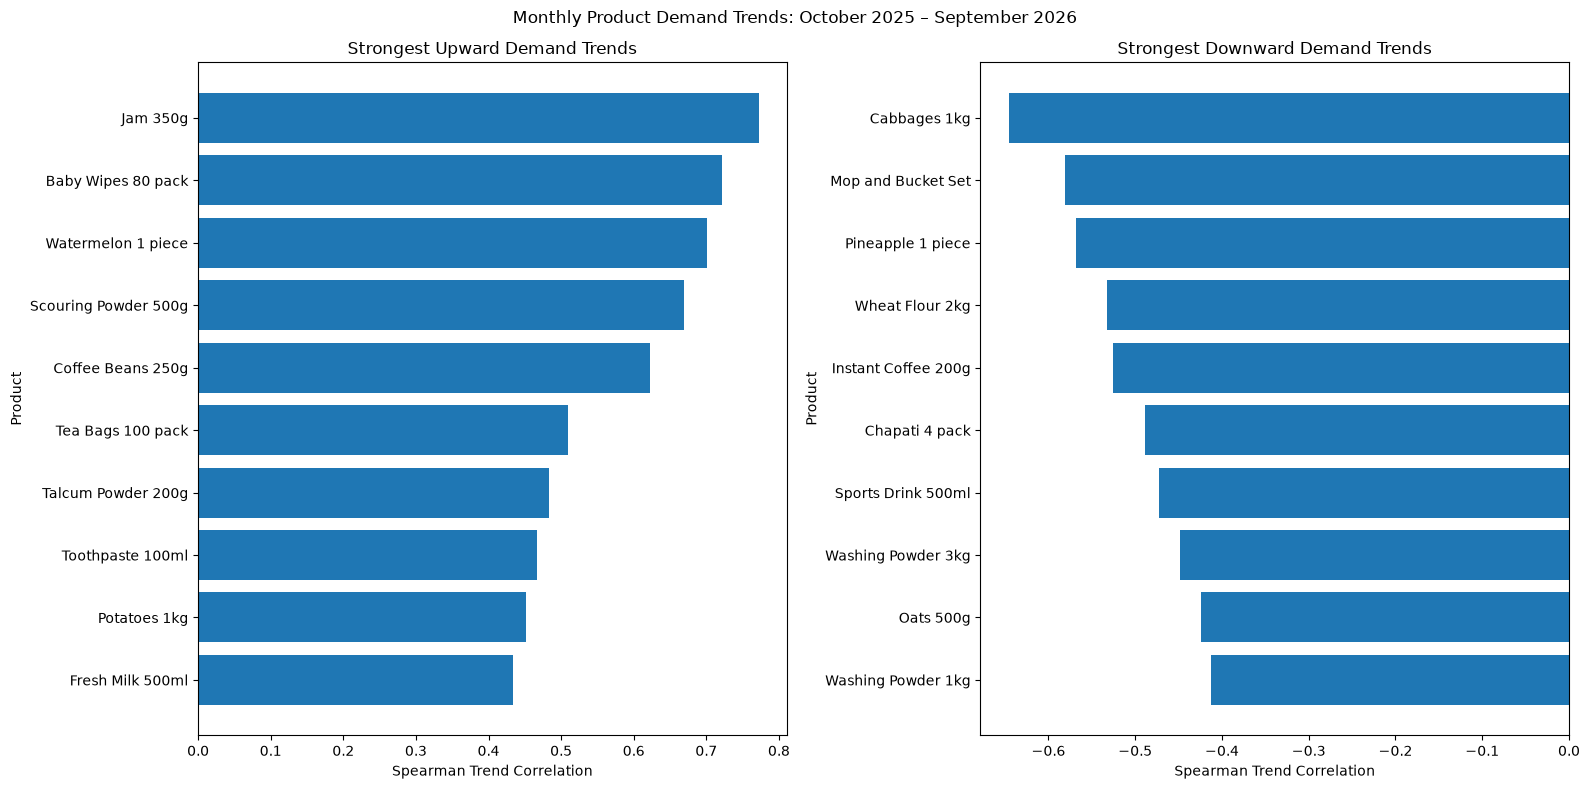

In [36]:

# 1. Calculate demand trends for each product
trend_results = []

for product_id, group in monthly_demand.groupby("ProductID"):
    group = group.sort_values("Month")

    correlation, p_value = stats.spearmanr(
        range(len(group)), group["QuantitySold"]
    )

    trend_results.append({
        "ProductID": product_id,
        "TrendCorrelation": round(correlation, 3),
        "PValue": round(p_value, 4)
    })

trend_results = pd.DataFrame(trend_results)

# 2. Add product names
trend_results = trend_results.merge(
    products[["ProductID", "ProductName"]].drop_duplicates("ProductID"),
    on="ProductID",
    how="left"
)

# 3. Select the strongest upward and downward trends
upward = trend_results.nlargest(10, "TrendCorrelation").sort_values("TrendCorrelation")
downward = trend_results.nsmallest(10, "TrendCorrelation").sort_values("TrendCorrelation", ascending=False)

# 4. Visualize demand trends without separate tables
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].barh(upward["ProductName"], upward["TrendCorrelation"])
axes[0].set_title("Strongest Upward Demand Trends")
axes[0].set_xlabel("Spearman Trend Correlation")
axes[0].set_ylabel("Product")

axes[1].barh(downward["ProductName"], downward["TrendCorrelation"])
axes[1].set_title("Strongest Downward Demand Trends")
axes[1].set_xlabel("Spearman Trend Correlation")
axes[1].set_ylabel("Product")

fig.suptitle("Monthly Product Demand Trends: October 2025 – September 2026")
plt.tight_layout()
plt.show()


The analysis examined monthly demand for 100 products over 12 months, from October 2025 to September 2026, using Spearman's rank correlation to identify upward and downward demand trends.

**Upward demand trends:** These products had positive trends with p-values below 0.05.

**Downward demand trends:** These two products had negative trends with p-values below 0.05. Pineapple also showed a negative trend (\(\rho = -0.568\)), but its p-value of 0.0541 was slightly above the 0.05 threshold.

**Interpretation:** The results indicate that demand developed differently across products during the study period. The upward trends identify products that may warrant closer attention when planning stock levels, while the downward trends highlight products whose sales patterns may need further investigation.